Testing Short Circuit Topology with Dynamic Sum...
Running 10000 iterations for GLV and Bounded models with dynamic c...
Average diversity for GLV: 2.4863
Average diversity for Bounded: 2.9085
Realizations where all three species survive in GLV: 4863, 48.63%
Realizations where all three species survive in Bounded: 9085, 90.85%


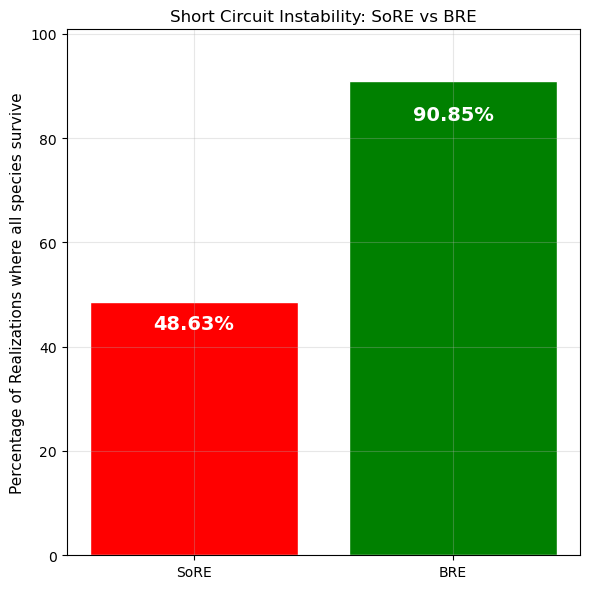

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# -----------------------------
# Global simulation parameters
# -----------------------------
x_min = 0.002
t_span = (0, 1000)
N_species = 3
max_iters = 10000

# Base intrinsic growth rate bounds
r_min, r_max = 0.01, 1.0

# -----------------------------
# Mathematical Fitness Functions
# -----------------------------
def glv_fitness(r, B, y):
    """ GLV fitness: f_i = r_i + sum_j B_ij y_j """
    return r + B @ y

def bounded_fitness(r, Alpha, y, eps=1e-12):
    """ Bounded fitness: f_i = r_i + sum_j Alpha_ij y_j / (y_i + y_j) """
    denom = y[:, None] + y[None, :] + eps
    ratio = y[None, :] / denom
    return r + np.sum(Alpha * ratio, axis=1)

# -----------------------------
# Standard Replicator ODE (Dynamic c)
# -----------------------------
def rhs_short_circuit_dynamic_c(t, y, model, A, r):
    y_safe = np.clip(y, 0.0, None)
    N = len(y_safe)

    # --- DYNAMIC TOTAL POPULATION ---
    c_dynamic = np.sum(y_safe)
    
    # Safety catch to prevent division by zero if all species die
    if c_dynamic <= 1e-12:
        return np.zeros_like(y_safe)

    if model == "GLV":
        # B matrix scaled dynamically as alpha_ij * (N / 2c)
        B = A * (N / (2.0 * c_dynamic))
        f = glv_fitness(r, B, y_safe)
    elif model == "Bounded":
        Alpha = A.copy()
        f = bounded_fitness(r, Alpha, y_safe)
    else:
        raise ValueError(f"Unknown model: {model}")

    # Coupled dilution term dynamically divided by the current sum
    dilution_term = np.dot(y_safe, f) / c_dynamic

    return y_safe * (f - dilution_term)

# -----------------------------
# Relaxation Solver
# -----------------------------
def relax_dynamics(A, x, r, model='Bounded'):
    def event_equilibrium(t, y):
        dydt = rhs_short_circuit_dynamic_c(t, y, model, A, r)
        y_safe = np.clip(y, 1e-12, None)
        rel_change = np.abs(dydt / y_safe)
        return np.max(rel_change) - 1e-8

    event_equilibrium.terminal = True
    event_equilibrium.direction = -1

    sol = solve_ivp(
        fun=lambda t, y: rhs_short_circuit_dynamic_c(t, y, model, A, r),
        t_span=t_span,
        y0=x,
        method='BDF',
        events=event_equilibrium,
        rtol=1e-6,
        atol=1e-9,
        max_step=2.0
    )

    x_final = np.clip(sol.y[:, -1], 0, None)
    s = x_final.sum()

    if s <= 0.0:
        return np.ones_like(x_final) / len(x_final)
    return x_final / s

# -----------------------------
# Short Circuit Instability Monte Carlo
# -----------------------------
def short_circuit_instability(edges, seed=2):
    np.random.seed(seed)

    # Build Adjacency Matrix
    A = np.zeros((N_species, N_species), dtype=float)
    for src, tgt in edges:
        A[tgt, src] = 1.0

    s1_glv_counts = []
    s1_v3_counts = []
    survivals_glv = 0
    survivals_v3 = 0
    r_vectors = []
    xs_v3 = []
    
    print(f"Running {max_iters} iterations for GLV and Bounded models with dynamic c...")
    for i in range(max_iters):
        r = np.random.uniform(r_min, r_max, size=N_species)
        x0 = np.random.rand(N_species)
        x0 = x0 / x0.sum()

        # Test GLV
        x_final_glv = relax_dynamics(A, x0, r, model='GLV')
        surviving_glv = np.sum(x_final_glv > x_min)
        s1_glv_counts.append(surviving_glv)
        if surviving_glv == N_species:
            survivals_glv += 1

        # Test Bounded Model
        x_final_v3 = relax_dynamics(A, x0, r, model='Bounded')
        surviving_v3 = np.sum(x_final_v3 > x_min)
        s1_v3_counts.append(surviving_v3)
        if surviving_v3 == N_species:
            survivals_v3 += 1
            
        r_vectors.append(r)
        xs_v3.append(x_final_v3)
        
    avg_div_glv = np.mean(s1_glv_counts)
    avg_div_v3 = np.mean(s1_v3_counts)
    pct_glv = (survivals_glv / max_iters) * 100
    pct_v3 = (survivals_v3 / max_iters) * 100

    print(f"Average diversity for GLV: {avg_div_glv:.4f}")
    print(f"Average diversity for Bounded: {avg_div_v3:.4f}")
    print(f"Realizations where all three species survive in GLV: {survivals_glv}, {pct_glv:.2f}%")
    print(f"Realizations where all three species survive in Bounded: {survivals_v3}, {pct_v3:.2f}%")

    return pct_glv, pct_v3, r_vectors, xs_v3

# -----------------------------
# Execution & Visualization
# -----------------------------
if __name__ == "__main__":
    # Short Circuit topology: 0 and 1 are a mutually catalyzing 2-cycle.
    # 1 feeds 2, and 2 feeds 0, creating a secondary longer loop.
    edges = [(0, 1), (1, 0), (1, 2), (2, 0)]

    print("Testing Short Circuit Topology with Dynamic Sum...")
    pct_glv, pct_v3, r_vectors, xs_v3 = short_circuit_instability(edges)

    # Plotting
    labels = ['SoRE', 'BRE']
    percentages = [pct_glv, pct_v3]
    
    # Optional: Update colors to match the red/green convention from your previous plots
    colors = ['red', 'green']

    fig, ax = plt.subplots(figsize=(6, 6))
    bars = ax.bar(labels, percentages, color=colors, edgecolor='white')

    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval - (yval * 0.05) if yval > 5 else yval + 1,
                f'{yval:.2f}%', ha='center', va='top' if yval > 5 else 'bottom',
                color='white' if yval > 5 else 'black',
                fontsize=14, fontweight='bold')

    ax.set_ylabel("Percentage of Realizations where all species survive", fontsize=11)
    ax.set_ylim(0, max(percentages) + 10)
    ax.grid(alpha=0.3)
    plt.title("Short Circuit Instability: SoRE vs BRE")
    plt.tight_layout()
    plt.show()

Testing Parasitic Topology with Dynamic Sum...
Running 10000 iterations for SoRE and BRE models with dynamic C...
Average diversity for SoRE: 1.6720
Average diversity for BRE: 2.7378
Realizations where all three species survive in SoRE: 85, 0.85%
Realizations where all three species survive in BRE: 8225, 82.25%


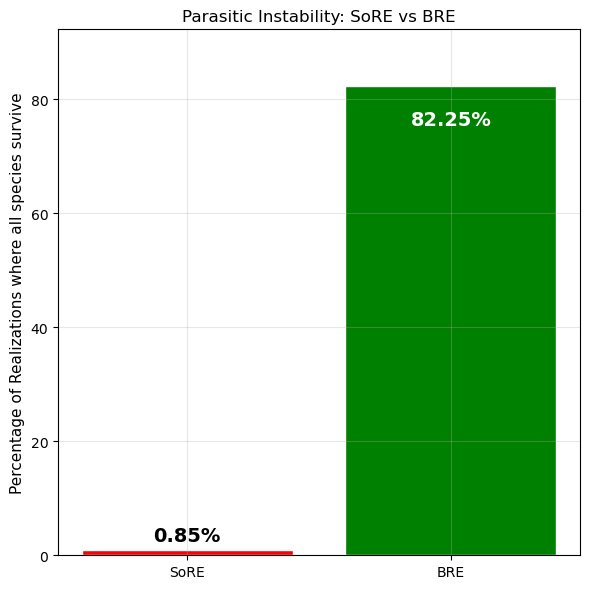

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# -----------------------------
# Global simulation parameters
# -----------------------------
x_min = 0.002
t_span = (0, 1000)
N_species = 3
max_iters = 10000

# Base intrinsic growth rate bounds
r_min, r_max = 0.01, 1.0

# -----------------------------
# Mathematical Fitness Functions
# -----------------------------
def sore_fitness(r, B, y):
    """ SoRE fitness: f_i = r_i + sum_j B_ij y_j """
    return r + B @ y

def bounded_fitness(r, Alpha, y, eps=1e-12):
    """ BRE fitness: f_i = r_i + sum_j Alpha_ij y_j / (y_i + y_j) """
    denom = y[:, None] + y[None, :] + eps
    ratio = y[None, :] / denom
    return r + np.sum(Alpha * ratio, axis=1)

# -----------------------------
# Standard Replicator ODE (Dynamic C)
# -----------------------------
def rhs_dynamic_c(t, y, model, A, r):
    y_safe = np.clip(y, 0.0, None)
    N = len(y_safe)

    # --- DYNAMIC TOTAL POPULATION ---
    c_dynamic = np.sum(y_safe)
    
    # Safety catch to prevent division by zero if all species die
    if c_dynamic <= 1e-12:
        return np.zeros_like(y_safe)

    if model == "SoRE":
        # B matrix scaled dynamically as alpha_ij * (N / 2c)
        B = A * (N / (2.0 * c_dynamic))
        f = sore_fitness(r, B, y_safe)
    elif model == "BRE":
        Alpha = A.copy()
        f = bounded_fitness(r, Alpha, y_safe)
    else:
        raise ValueError(f"Unknown model: {model}")

    # Coupled dilution term dynamically divided by the current sum
    dilution_term = np.dot(y_safe, f) / c_dynamic

    return y_safe * (f - dilution_term)

# -----------------------------
# Relaxation Solver
# -----------------------------
def relax_dynamics(A, x, r, model='BRE'):
    def event_equilibrium(t, y):
        dydt = rhs_dynamic_c(t, y, model, A, r)
        y_safe = np.clip(y, 1e-12, None)
        rel_change = np.abs(dydt / y_safe)
        return np.max(rel_change) - 1e-8

    event_equilibrium.terminal = True
    event_equilibrium.direction = -1

    sol = solve_ivp(
        fun=lambda t, y: rhs_dynamic_c(t, y, model, A, r),
        t_span=t_span,
        y0=x,
        method='BDF',
        events=event_equilibrium,
        rtol=1e-6,
        atol=1e-9,
        max_step=2.0
    )

    x_final = np.clip(sol.y[:, -1], 0, None)
    s = x_final.sum()

    if s <= 0.0:
        return np.ones_like(x_final) / len(x_final)
    return x_final / s

# -----------------------------
# Parasitic Instability Monte Carlo
# -----------------------------
def parasitic_instability(edges, seed=2):
    np.random.seed(seed)

    # Build Adjacency Matrix
    A = np.zeros((N_species, N_species), dtype=float)
    for src, tgt in edges:
        A[tgt, src] = 1.0

    s1_sore_counts = []
    s1_bre_counts = []
    survivals_sore = 0
    survivals_bre = 0
    r_vectors = []
    xs_bre = []
    
    print(f"Running {max_iters} iterations for SoRE and BRE models with dynamic C...")
    for i in range(max_iters):
        r = np.random.uniform(r_min, r_max, size=N_species)
        x0 = np.random.rand(N_species)
        x0 = x0 / x0.sum()

        # Test SoRE
        x_final_sore = relax_dynamics(A, x0, r, model='SoRE')
        surviving_sore = np.sum(x_final_sore > x_min)
        s1_sore_counts.append(surviving_sore)
        if surviving_sore == N_species:
            survivals_sore += 1

        # Test BRE
        x_final_bre = relax_dynamics(A, x0, r, model='BRE')
        surviving_bre = np.sum(x_final_bre > x_min)
        s1_bre_counts.append(surviving_bre)
        if surviving_bre == N_species:
            survivals_bre += 1
            
        r_vectors.append(r)
        xs_bre.append(x_final_bre)
        
    avg_div_sore = np.mean(s1_sore_counts)
    avg_div_bre = np.mean(s1_bre_counts)
    pct_sore = (survivals_sore / max_iters) * 100
    pct_bre = (survivals_bre / max_iters) * 100

    print(f"Average diversity for SoRE: {avg_div_sore:.4f}")
    print(f"Average diversity for BRE: {avg_div_bre:.4f}")
    print(f"Realizations where all three species survive in SoRE: {survivals_sore}, {pct_sore:.2f}%")
    print(f"Realizations where all three species survive in BRE: {survivals_bre}, {pct_bre:.2f}%")

    return pct_sore, pct_bre, r_vectors, xs_bre

# -----------------------------
# Execution & Visualization
# -----------------------------
if __name__ == "__main__":
    # Parasitic topology: 0 and 1 are a mutually catalyzing 2-cycle.
    # 1 feeds 2 (the parasite), but 2 gives nothing back to the network.
    edges = [(0, 1), (1, 0), (1, 2)]

    print("Testing Parasitic Topology with Dynamic Sum...")
    pct_sore, pct_bre, r_vectors, xs_bre = parasitic_instability(edges)

    # Plotting
    labels = ['SoRE', 'BRE']
    percentages = [pct_sore, pct_bre]
    colors = ['red', 'green']

    fig, ax = plt.subplots(figsize=(6, 6))
    bars = ax.bar(labels, percentages, color=colors, edgecolor='white')

    for bar in bars:
        yval = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, yval - (yval * 0.05) if yval > 5 else yval + 1,
                f'{yval:.2f}%', ha='center', va='top' if yval > 5 else 'bottom',
                color='white' if yval > 5 else 'black',
                fontsize=14, fontweight='bold')

    ax.set_ylabel("Percentage of Realizations where all species survive", fontsize=11)
    ax.set_ylim(0, max(percentages) + 10)
    ax.grid(alpha=0.3)
    plt.title("Parasitic Instability: SoRE vs BRE")

    plt.tight_layout()
    plt.show()

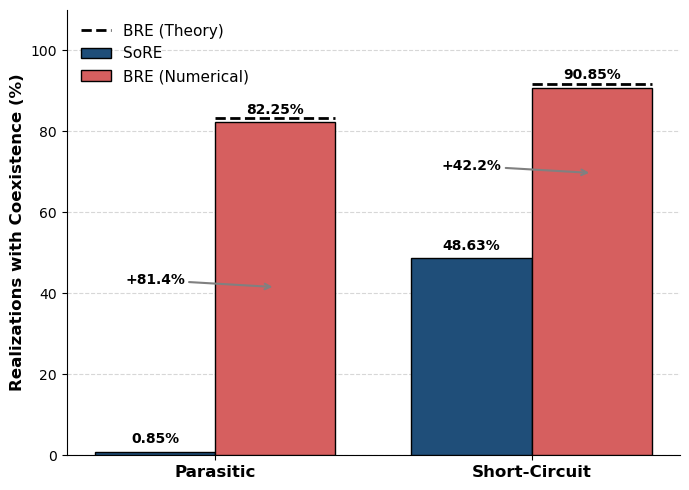

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Data
architectures = ['Parasitic', 'Short-Circuit']
#sore_survival = [9.47, 51.09]
#bre_survival = [84.36, 91.44]
sore_survival = [0.85,48.63]
bre_survival = [82.25,90.85]
bre_theory = [83.33, 91.67] # Analytical benchmarks

x = np.arange(len(architectures))
width = 0.38 # Slightly adjusted for a clean, touching grouped look

# High-contrast, colorblind-friendly academic palette
color_sore = '#1f4e79' # Deep Navy Blue
color_bre = '#d65f5f'  # Muted Coral/Red

fig, ax = plt.subplots(figsize=(7, 5))

# Plot bars
rects1 = ax.bar(x - width/2, sore_survival, width, label='SoRE', color=color_sore, edgecolor='black', zorder=3)
rects2 = ax.bar(x + width/2, bre_survival, width, label='BRE (Numerical)', color=color_bre, edgecolor='black', zorder=3)

# Overlay Theoretical Benchmarks as dashed lines over the BRE bars
for i in range(len(architectures)):
    # Calculate the left and right edges of the BRE bar
    left_edge = x[i]
    right_edge = x[i] + width
    ax.hlines(bre_theory[i], left_edge, right_edge, color='black', linestyle='--', 
              linewidth=2, zorder=4, label='BRE (Theory)' if i == 0 else "")

# Styling
ax.set_ylabel('Realizations with Coexistence (%)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=12, fontweight='bold')
ax.set_ylim(0, 110)

# Clean up axes (remove top and right spines for a modern academic look)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

# Custom Legend
ax.legend(frameon=False, fontsize=11, loc='upper left')

# Auto-label function for percentage text on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),  # 4 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=10)

autolabel(rects1)
autolabel(rects2)

# Emphasize the "Delta" (Improvement) with subtle arrows
for i in range(len(architectures)):
    delta = bre_survival[i] - sore_survival[i]
    # Draw a subtle arrow from SoRE bar to BRE bar
    ax.annotate(f'+{delta:.1f}%',
                xy=(x[i] + width/2, sore_survival[i] + delta/2), 
                xytext=(x[i] - width/2, sore_survival[i] + delta/2),
                arrowprops=dict(arrowstyle="->", color='gray', lw=1.5),
                ha='center', va='bottom', fontsize=10, color='black', 
                fontweight='bold', zorder=5, bbox=dict(facecolor='white', edgecolor='none', pad=1, alpha=0.7))

plt.tight_layout()
plt.savefig('figures/combined_coexistence_bar_enhanced.pdf', format='pdf',dpi=300)
plt.show()

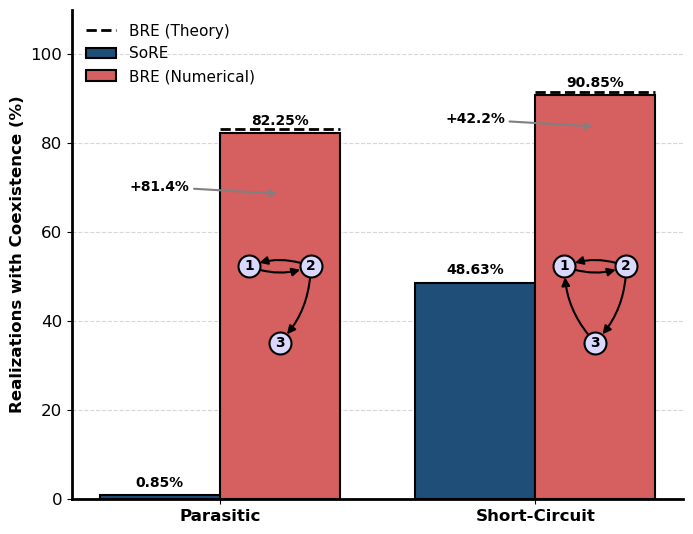

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import networkx as nx

# Enforce Frontiers Style Guidelines 
plt.rcParams.update({
    'font.size': 12,
    'axes.linewidth': 2.0,
    'lines.linewidth': 2.0,
    'lines.markeredgewidth': 2.0,
    'pdf.fonttype': 42,
    'ps.fonttype': 42
})

# Data
architectures = ['Parasitic', 'Short-Circuit']
sore_survival = [0.85, 48.63]
bre_survival = [82.25, 90.85]
bre_theory = [83.33, 91.67] 

x = np.arange(len(architectures))
width = 0.38 

color_sore = '#1f4e79' 
color_bre = '#d65f5f'  

fig, ax = plt.subplots(figsize=(7.09, 5.5))

# Plot bars
rects1 = ax.bar(x - width/2, sore_survival, width, label='SoRE', color=color_sore, edgecolor='black', zorder=3, lw=1.5)
rects2 = ax.bar(x + width/2, bre_survival, width, label='BRE (Numerical)', color=color_bre, edgecolor='black', zorder=3, lw=1.5)

# Overlay Theoretical Benchmarks
for i in range(len(architectures)):
    left_edge = x[i]
    right_edge = x[i] + width
    ax.hlines(bre_theory[i], left_edge, right_edge, color='black', linestyle='--', 
              linewidth=2, zorder=4, label='BRE (Theory)' if i == 0 else "")

# Styling
ax.set_ylabel('Realizations with Coexistence (%)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(architectures, fontsize=12, fontweight='bold')
ax.set_ylim(0, 110) 

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5, zorder=0)

ax.legend(frameon=False, fontsize=11, loc='upper left')

# Auto-label function
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 4),  
                    textcoords="offset points",
                    fontweight='bold',
                    ha='center', va='bottom', fontsize=10)

autolabel(rects1)
autolabel(rects2)

# Arrows for Delta
for i in range(len(architectures)):
    delta = bre_survival[i] - sore_survival[i]
    ax.annotate(f'+{delta:.1f}%',
                xy=(x[i] + width/2, sore_survival[i] + delta/(1.2)), 
                xytext=(x[i] - width/2, sore_survival[i] + delta/(1.2)),
                arrowprops=dict(arrowstyle="->", color='gray', lw=1.5),
                ha='center', va='bottom', fontsize=10, color='black', fontweight='bold',
                zorder=5, bbox=dict(facecolor='white', edgecolor='none', pad=1, alpha=0.7))


# =====================================================================
# INSET NETWORK TOPOLOGIES
# =====================================================================

# 1. Perfect Equilateral Triangle Coordinates
node_pos = {1: (-0.75, 0.65), 2: (0.75, 0.65), 3: (0, -0.25)}

# 2. Styling (Hex #D9D9FF is the exact RGB match for LaTeX's blue!15)
node_options = {"node_color": "#D9D9FF", "edgecolors": "black", "node_size": 250, "linewidths": 1.5}
base_arrow_opts = {"arrowsize": 12, "width": 1.5, "edge_color": "black", "node_size": 250}

# --- Parasitic network Inset ---
bar1_center = x[0] + width/2
ax_in1 = ax.inset_axes([bar1_center - 0.15, 20, 0.3, 40], transform=ax.transData)
ax_in1.axis('off')

# Explicitly pad the axis limits to prevent node cutoff
ax_in1.set_xlim(-1.15, 1.15)
ax_in1.set_ylim(-1.05, 1.05)

G_parasitic = nx.DiGraph()
G_parasitic.add_nodes_from([1, 2, 3])

nx.draw_networkx_nodes(G_parasitic, node_pos, ax=ax_in1, **node_options)
nx.draw_networkx_labels(G_parasitic, node_pos, ax=ax_in1, font_size=10, font_weight="bold")

nx.draw_networkx_edges(G_parasitic, node_pos, ax=ax_in1, edgelist=[(1, 2), (2, 1)], 
                       connectionstyle="arc3,rad=0.2", **base_arrow_opts)
nx.draw_networkx_edges(G_parasitic, node_pos, ax=ax_in1, edgelist=[(2, 3)], 
                       connectionstyle="arc3,rad=-0.2", **base_arrow_opts)

# --- Short-Circuit Network Inset ---
bar2_center = x[1] + width/2
ax_in2 = ax.inset_axes([bar2_center - 0.15, 20, 0.3, 40], transform=ax.transData)
ax_in2.axis('off')

# Explicitly pad the axis limits to prevent node cutoff
ax_in2.set_xlim(-1.15, 1.15)
ax_in2.set_ylim(-1.05, 1.05)

G_short = nx.DiGraph()
G_short.add_nodes_from([1, 2, 3])

nx.draw_networkx_nodes(G_short, node_pos, ax=ax_in2, **node_options)
nx.draw_networkx_labels(G_short, node_pos, ax=ax_in2, font_size=10, font_weight="bold")

nx.draw_networkx_edges(G_short, node_pos, ax=ax_in2, edgelist=[(1, 2), (2, 1)], 
                       connectionstyle="arc3,rad=0.2", **base_arrow_opts)
nx.draw_networkx_edges(G_short, node_pos, ax=ax_in2, edgelist=[(2, 3), (3, 1)], 
                       connectionstyle="arc3,rad=-0.2", **base_arrow_opts)

plt.tight_layout()
plt.savefig('figures/combined_coexistence_bar_enhanced.pdf', format='pdf', bbox_inches="tight")
plt.show()